In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/hassanzeeshan/data-science-job/data_science_job.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

In [4]:
df=pd.read_csv('/kaggle/input/datasets/hassanzeeshan/data-science-job/data_science_job.csv')

In [5]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  18679 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  float64
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  training_hours          18392 non-null  float64
 12  target                  19158 non-null  float64
dtypes: float64(4), int64(1), object(8)
memory usage: 1.9+ MB


In [7]:
df.isnull().sum()

enrollee_id                  0
city                         0
city_development_index     479
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
training_hours             766
target                       0
dtype: int64

In [8]:
df.isnull().mean()*100

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

In [9]:
df.shape

(19158, 13)

In [10]:
cols=[var for var in df.columns if df[var].isnull().mean() < 0.05  and df[var].isnull().mean() > 0]

In [11]:
cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [12]:
df[cols].sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
1255,0.920,Full time course,Graduate,5.0,30.0
12526,0.855,no_enrollment,Masters,2.0,111.0
4270,0.939,Full time course,Phd,20.0,50.0
7894,0.920,Full time course,Graduate,9.0,78.0
12418,0.920,no_enrollment,Masters,13.0,70.0


In [13]:
len(df[cols].dropna())/len(df)

0.8968577095730244

In [14]:
new_df=df[cols].dropna()

In [15]:
df.shape, new_df.shape

((19158, 13), (17182, 5))

array([[<Axes: title={'center': 'city_development_index'}>,
        <Axes: title={'center': 'experience'}>],
       [<Axes: title={'center': 'training_hours'}>, <Axes: >]],
      dtype=object)

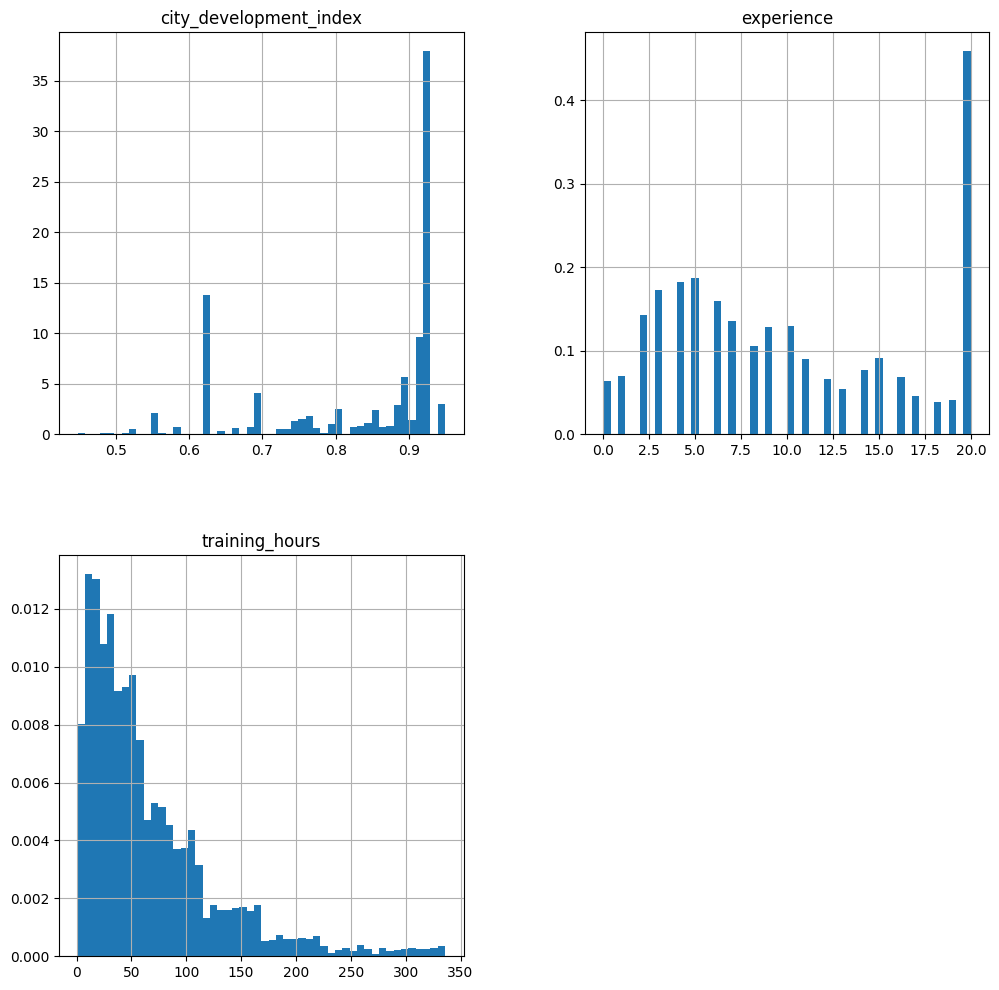

In [17]:
new_df.hist(bins=50, density=True, figsize=(12,12))

Text(0.5, 1.0, 'Before & After Complete Case Analysis')

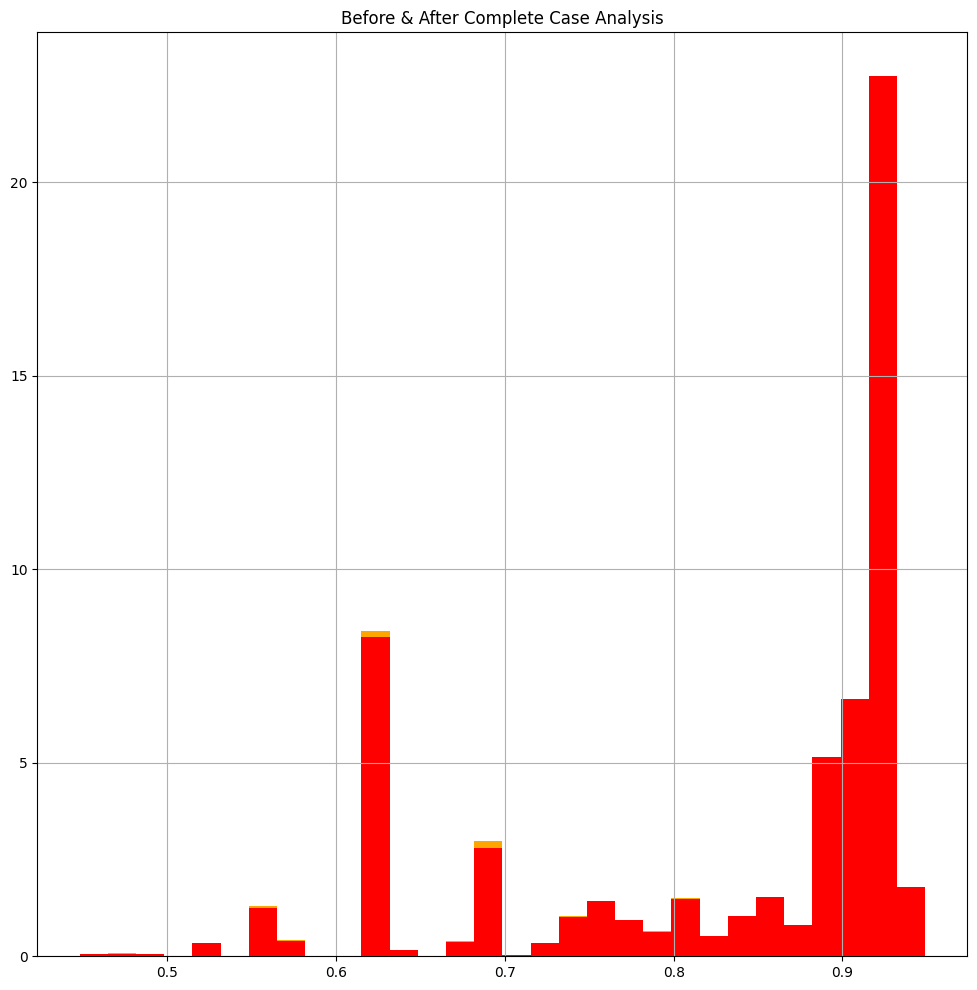

In [25]:
fig=plt.figure()
ax=fig.add_subplot(111)


df['city_development_index'].hist(bins=30, density=True, ax=ax, color='orange', figsize=(12,12))



new_df['city_development_index'].hist(bins=30, density=True, ax=ax, color='red')
plt.title('Before & After Complete Case Analysis')

Text(0.5, 1.0, 'Before & After Complete Case Analysis')

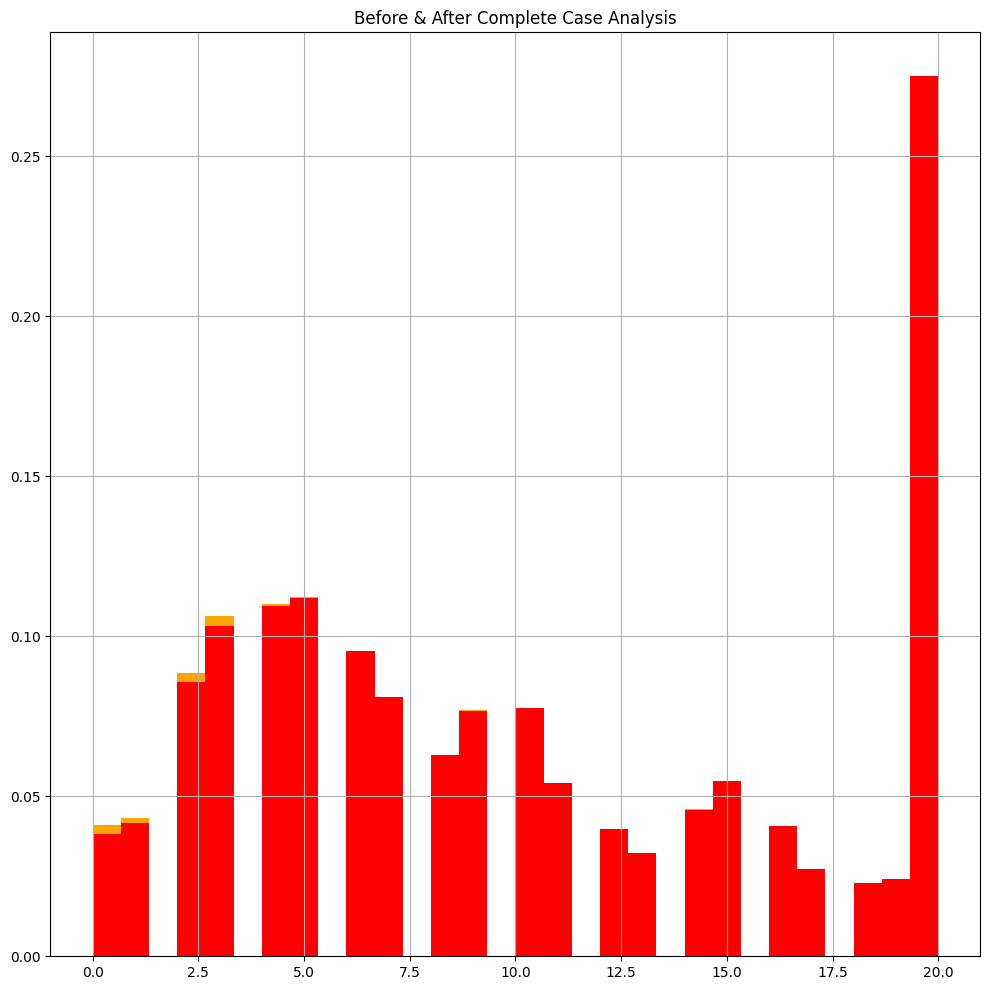

In [26]:
fig=plt.figure()
ax=fig.add_subplot(111)


df['experience'].hist(bins=30, density=True, ax=ax, color='orange', figsize=(12,12))




new_df['experience'].hist(bins=30, density=True, ax=ax, color='red')
plt.title('Before & After Complete Case Analysis')

<Axes: ylabel='Density'>

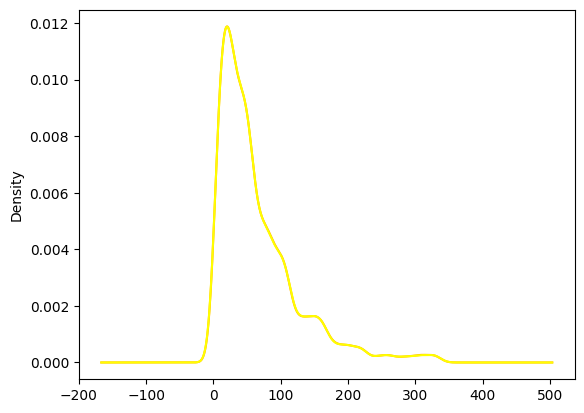

In [27]:
fig=plt.figure()
ax=fig.add_subplot(111)


df['training_hours'].plot.density(color='orange')



new_df['training_hours'].plot.density(color='yellow')


# now check the categorical ratio before and after the complete case analysis (CCA)a

In [28]:
tem1=pd.concat([
    
    #ratio before cca

    df['enrolled_university'].value_counts()/len(df),
    
     #ratio after cca
    
    new_df['enrolled_university'].value_counts()/len(new_df)
    ], axis=1)

tem1.columns=['original','cca']

In [29]:
tem1

,original,cca
enrolled_university,,
no_enrollment,0.721213,0.735188
Full time course,0.196106,0.200733
Part time course,0.062533,0.064079


In [30]:
tem2=pd.concat([
    
    #ratio before cca

    df['education_level'].value_counts()/len(df),
    
     #ratio after cca
    
    new_df['education_level'].value_counts()/len(new_df)
    ], axis=1)

tem2.columns=['original','cca']

In [31]:
tem2

,original,cca
education_level,,
Graduate,0.605387,0.619835
Masters,0.227633,0.234082
High School,0.105282,0.107380
Phd,0.021610,0.022116
Primary School,0.016077,0.016587
